# IPL Phase-Performance and Style-Drift Data Warehouse
**Data Wrangling group project · B.Tech CSE (Data Science), NMIMS MPSTME · Semester V (2026-27)**

Group members: Sanjeet Singh Tuteja (L076) · _[Member 2 name, roll no.]_ · _[Member 3 name, roll no.]_

## Objective
We take seventeen seasons of public IPL ball-by-ball data (2008–2024) through the full wrangling
pipeline (extraction, cleaning, transformation and loading into a SQLite star schema), then use the
wrangled data for insights, a classification model and a Power BI dashboard.

The project asks two questions:

1. **Style drift.** Does the phase of the innings in which a player mostly bats or bowls
   (Powerplay overs 1–6, Middle 7–15, Death 16–20) stay the same from season to season? Who
   changes, and how often?
2. **Powerplay signal.** How much of a match result can be predicted from the first six overs of
   each innings?

This notebook runs end to end from the two raw CSV files. The heavy lifting lives in the `src/`
package so the same code is used by the notebook, the command-line pipeline and the tests. Every
stage is shown here with its outputs.

In [1]:
import os, sys, sqlite3, zipfile, urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import Image, display

REPO = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(REPO))

from src import analysis, extract, ml, pipeline, powerbi
from src.config import PHASES, QUALIFY_BALLS, Paths

P = Paths(root=REPO)
RAW, LOGS, EXPORT = P.raw, P.logs, P.export
pd.set_option("display.max_columns", 40, "display.width", 200, "display.max_colwidth", 70)
print("Project root:", REPO)

Project root: /home/claude/dw-project


## 1. Data extraction

**Source.** *IPL Complete Dataset (2008–2024)* by Prateek Bhardwaj on Kaggle (dataset version 3,
last updated 8 June 2024): two files, `matches.csv` (one row per match) and `deliveries.csv` (one
row per ball). The ball-by-ball records originate from **Cricsheet** (cricsheet.org).

**How it was obtained.** A direct download of the dataset archive from Kaggle's public download
endpoint (the cell below). Public datasets download without an API key through this endpoint; if
it is blocked, the same two files can be downloaded by hand from the dataset page after signing in.

**Access constraints and licence.** No rate limits were hit (one 1.9 MB request). The Kaggle
dataset is published under the Open Database License (database) and Database Contents License
(contents); the underlying Cricsheet data is under the Open Data Commons Attribution License, so
both sources are credited. The data is used for coursework and analysis only, not for wagering.

The raw files are never edited. They are read as text, checksummed and copied unchanged into
staging tables, so every later number can be traced back to a file hash (step E1).

In [2]:
SOURCE_URL = "https://www.kaggle.com/datasets/patrickb1912/ipl-complete-dataset-20082020"
API_URL = "https://www.kaggle.com/api/v1/datasets/download/patrickb1912/ipl-complete-dataset-20082020"
DATASET_VERSION = "Kaggle version 3 (files dated 2024-06-08)"
DOWNLOAD_DATE = "2026-10-18"

if not all((RAW / f).exists() for f in ("matches.csv", "deliveries.csv")):
    RAW.mkdir(parents=True, exist_ok=True)
    archive = RAW / "ipl_archive.zip"
    urllib.request.urlretrieve(API_URL, archive)
    with zipfile.ZipFile(archive) as z:
        z.extractall(RAW)
    archive.unlink()

for f in ("matches.csv", "deliveries.csv"):
    p = RAW / f
    print(f"{f:15s} {p.stat().st_size / 1e6:6.1f} MB   sha256 {extract.sha256(p)[:20]}...")

raw_m = extract.read_raw(RAW / "matches.csv")
raw_d = extract.read_raw(RAW / "deliveries.csv")
print("matches:", raw_m.shape, "  deliveries:", raw_d.shape)
raw_m.head(3)

matches.csv        0.2 MB   sha256 8a0394246d2a76b44526...
deliveries.csv    27.0 MB   sha256 142236ea52950795dab2...


matches: (1095, 20)   deliveries: (260920, 17)


,id,season,city,date,match_type,player_of_match,venue,team1,team2,toss_winner,toss_decision,winner,result,result_margin,target_runs,target_overs,super_over,method,umpire1,umpire2
0,335982,2007/08,Bangalore,2008-04-18,League,BB McCullum,M Chinnaswamy Stadium,Royal Challengers Bangalore,Kolkata Knight Riders,Royal Challengers Bangalore,field,Kolkata Knight Riders,runs,140,223,20,N,NA,Asad Rauf,RE Koertzen
1,335983,2007/08,Chandigarh,2008-04-19,League,MEK Hussey,"Punjab Cricket Association Stadium, Mohali",Kings XI Punjab,Chennai Super Kings,Chennai Super Kings,bat,Chennai Super Kings,runs,33,241,20,N,NA,MR Benson,SL Shastri
2,335984,2007/08,Delhi,2008-04-19,League,MF Maharoof,Feroz Shah Kotla,Delhi Daredevils,Rajasthan Royals,Rajasthan Royals,bat,Delhi Daredevils,wickets,9,130,20,N,NA,Aleem Dar,GA Pratapkumar


In [3]:
raw_d.head(3)

,match_id,inning,batting_team,bowling_team,over,ball,batter,bowler,non_striker,batsman_runs,extra_runs,total_runs,extras_type,is_wicket,player_dismissed,dismissal_kind,fielder
0,335982,1,Kolkata Knight Riders,Royal Challengers Bangalore,0,1,SC Ganguly,P Kumar,BB McCullum,0,1,1,legbyes,0,NA,NA,NA
1,335982,1,Kolkata Knight Riders,Royal Challengers Bangalore,0,2,BB McCullum,P Kumar,SC Ganguly,0,0,0,,0,NA,NA,NA
2,335982,1,Kolkata Knight Riders,Royal Challengers Bangalore,0,3,BB McCullum,P Kumar,SC Ganguly,0,1,1,wides,0,NA,NA,NA


### 1.1 Why this dataset needs wrangling
Before writing any cleaning code we profiled the raw text for the problems we expected. The cell
below shows each one with evidence from the raw files.

In [4]:
teams = sorted(set(raw_m.team1) | set(raw_m.team2))
print(f"{len(teams)} distinct team strings, e.g. renames and a spelling variant:")
print("  ", [t for t in teams if any(k in t for k in ("Delhi", "Punjab", "Pune", "Royal", "Deccan"))])

print("\nSeason labels that are not a plain year:", sorted(s for s in raw_m.season.unique() if not s.isdigit()))

v = raw_m.venue.value_counts()
print(f"\n{v.size} distinct venue strings; the same grounds appear under several names, e.g.:")
print("  ", sorted(x for x in v.index if any(k in x for k in ("Chinnaswamy", "Kotla", "Arun Jaitley", "Zayed"))))

overs = raw_d.over.astype(int)
print(f"\nOver numbers run {overs.min()}..{overs.max()} (0-based); the phases are defined on overs 1-20.")

na = {c: int((raw_m[c] == "NA").sum()) for c in raw_m.columns if (raw_m[c] == "NA").any()}
print("\n'NA' text tokens in matches.csv:", na)
print("matches with no city:", int((raw_m.city.isin(["", "NA"])).sum()))

print("\nextras_type:", raw_d.extras_type.replace("", "(blank)").value_counts().to_dict())

19 distinct team strings, e.g. renames and a spelling variant:
   ['Deccan Chargers', 'Delhi Capitals', 'Delhi Daredevils', 'Kings XI Punjab', 'Pune Warriors', 'Punjab Kings', 'Rajasthan Royals', 'Rising Pune Supergiant', 'Rising Pune Supergiants', 'Royal Challengers Bangalore', 'Royal Challengers Bengaluru']

Season labels that are not a plain year: ['2007/08', '2009/10', '2020/21']

58 distinct venue strings; the same grounds appear under several names, e.g.:
   ['Arun Jaitley Stadium', 'Arun Jaitley Stadium, Delhi', 'Feroz Shah Kotla', 'M Chinnaswamy Stadium', 'M Chinnaswamy Stadium, Bengaluru', 'M.Chinnaswamy Stadium', 'Sheikh Zayed Stadium', 'Zayed Cricket Stadium, Abu Dhabi']

Over numbers run 0..19 (0-based); the phases are defined on overs 1-20.

'NA' text tokens in matches.csv: {'city': 51, 'player_of_match': 5, 'winner': 5, 'result_margin': 19, 'target_runs': 3, 'target_overs': 3, 'method': 1074}
matches with no city: 51

extras_type: {'(blank)': 246795, 'wides': 8380, 'legby

So the raw data has renamed and misspelt teams, one ground under up to five names, missing cities,
text season labels such as `2007/08` (which is actually IPL 2008), 0-based overs, `NA` strings
instead of nulls, and wides and no-balls that must not count as legal balls. None of this is
visible from a quick `df.describe()`, and each one changes the answers if left alone.

## 2. Run the ETL pipeline (E1–E12)

`pipeline.run` executes every step and stops before exporting if any of the nine validation gates
fails. The sections after this cell open up each stage and show what it did.

| Step | What it does |
|---|---|
| E1–E2 | Register raw files (SHA-256, row counts) and stage them unchanged in SQLite |
| E3 | Profile every column; test the ten expected data-quality issues |
| E4–E6 | Canonicalise teams, venues, cities and players; normalise types; derive flags |
| E7–E10 | Build dimensions, three fact tables and the SCD Type 2 player-phase profile |
| E11 | Validation gates G1–G9 |
| E12 | Export analysis tables and the ML feature table |

In [5]:
exit_code = pipeline.run(P, source_url=SOURCE_URL, dataset_version=DATASET_VERSION, download_date=DOWNLOAD_DATE)
assert exit_code == 0, "a validation gate failed - see logs/validation_report.csv"

[15:53:11] E1 register raw files


[15:53:12] E2 stage


[15:53:14] E3 profile


[15:53:17]   8/10 expected issues confirmed


[15:53:17] E4-E6 canonicalise, normalise, flag


...

[15:53:23]   G8 PASS: 0 overlapping spell pairs; 0 player-roles without exactly one current row; 0 rows with inconsistent is_current


[15:53:23]   G9 PASS: raw deliveries=260920; stg_deliveries=260920; clean_deliveries=260920; fact_delivery=260920; raw matches=1095; stg_matches=1095; dim_match=1095; fact_match_summary=1095; deliveries for unknown matches=0


[15:53:23] E12 export


[15:53:26]   540 phase changes in the drift table; exports in /home/claude/dw-project/data/export


[15:53:26] DONE: all gates passed


In [6]:
pd.read_csv(LOGS / "extraction_log.csv").tail(2)[
    ["file", "source_url", "dataset_version", "download_date", "sha256", "rows", "columns"]]

,file,source_url,dataset_version,download_date,sha256,rows,columns
0,matches.csv,https://www.kaggle.com/datasets/patrickb1912/ipl-complete-dataset-...,Kaggle version 3 (files dated 2024-06-08),2026-10-18,8a0394246d2a76b44526565f2245d8f4feff91babe57ab16676a2c3d67aa0846,1095,20
1,deliveries.csv,https://www.kaggle.com/datasets/patrickb1912/ipl-complete-dataset-...,Kaggle version 3 (files dated 2024-06-08),2026-10-18,142236ea52950795dab266d4aa392c7645bd1a0db4704f0b8058afd96e24e2c2,260920,17


### 2.1 Profiling result: the ten expected issues

In [7]:
pd.read_csv(LOGS / "data_quality_findings.csv")

,issue,description,status,evidence
0,1,Franchise renames and defunct teams,CONFIRMED,Deccan Chargers; Delhi Daredevils; Kings XI Punjab; Kochi Tuskers ...
1,2,Spelling variants of the same team,CONFIRMED,Rising Pune Supergiant / Rising Pune Supergiants
2,3,`method` column almost entirely null,CONFIRMED,98.1% null
3,4,"No-result, tied and Super Over matches",CONFIRMED,"no result=5, tie=14, super_over=Y: 14"
4,5,Player name variants,NOT FOUND,0 name keys with >1 spelling; 732 raw names
5,6,Venue name variants and missing city,CONFIRMED,58 raw venues -> 41 keys; 51 matches without city
6,7,Season stored as text; over numbering base,CONFIRMED,"non-integer seasons: ['2007/08', '2009/10', '2020/21']; over min=0..."
7,8,Wides and no-balls affect legal-ball counts,CONFIRMED,"wides=8380, noballs=1069"
8,9,Structural nulls in event columns,CONFIRMED,"{'extras_type': 94.6, 'player_dismissed': 95.0, 'dismissal_kind': ..."
9,10,"(match, inning, over, ball) not unique",NOT FOUND,0 duplicate keys


Eight of the ten expected issues were confirmed. Two were not: player names in this version of the
data are already consistent (Cricsheet uses one registered name per player), and the
`(match, inning, over, ball)` key happens to be unique here, but only because extras re-use ball
numbers in a way we cannot rely on; we still use our own `delivery_seq` key (section 4).

## 3. Data cleaning

### 3.1 Cleaning log
Every rule writes a row to `logs/cleaning_log.csv` with the raw value, the clean value and the
number of rows changed.

In [8]:
log = pd.read_csv(LOGS / "cleaning_log.csv")
print(len(log), "logged cleaning rules,", f"{log.rows_affected.sum():,}", "cell changes in total")
log.groupby(["step", "rule"]).agg(rules=("rule", "size"), rows_affected=("rows_affected", "sum")) \
   .sort_values("rows_affected", ascending=False)

54 logged cleaning rules, 1,755,214 cell changes in total


rules  rows_affected
step rule                                                       
E5   null token -> NULL                        11         995461
     structural null -> 'none'                  2         494765
     shift 0-based overs to 1-20                1         260920
E4   team canonical name                        6           3221
     venue canonical name (manual)             15            367
E5   season label -> year of match date         3            178
E4   venue canonical name (normalised key)     11            160
     city canonical name                        2             70
     fill city from venue mapping               2             51
E6   derive is_dl_applied; drop raw column      1             21

### 3.2 What we found, what we did, and why

| Problem | Evidence | Decision | Why this method |
|---|---|---|---|
| `NA` / blank text tokens | 1,074 `method`, 51 `city`, ~95% of the dismissal columns | Convert to real NULLs | They are missing-value markers, not values |
| Structural nulls (`extras_type`, `dismissal_kind`, `player_dismissed`, `fielder`) | ~95% null | **Flag** as the category `none`; never impute | Absence means "no extra / no wicket"; imputing would invent events |
| Missing `city` | 51 matches (Dubai, Sharjah) | Filled from the venue mapping | Deterministic: the ground fixes the city, so this is a lookup, not a guess |
| Missing `winner`, `player_of_match`, `result_margin` | 5 no-results, 14 ties | **Kept NULL**; result coded in `match_status` | A no-result has no winner; filling it would be wrong |
| `method` (D/L) almost always null | 98.1% null | Converted to a 0/1 `is_dl_applied` flag; raw column dropped | The only information is "D/L or not" |
| Season stored as text (`2007/08`, `2009/10`, `2020/21`) | 178 matches | Season = calendar year of the match date (D-01) | The labels are ambiguous; the date is not |
| 0-based overs | over 0..19 | Shifted to 1..20 (D-02) | Phases are defined on 1–20 |
| Team renames and a misspelling | 19 raw names | Spelling variants merged; renames kept as **SCD Type 2** spells of one franchise (D-03) | A rename is history, not an error; the franchise id keeps them together |
| Venue variants | 58 raw strings → 36 grounds | Hand-checked mapping table; renamed grounds merged (D-04) | Venue effects must compare the same physical ground |
| Player name variants | 30 fuzzy pairs proposed | **Left as-is**: merged only on an identical letters-and-digits key (D-05) | 13 of the 30 pairs played in the same match, so they are different people; the rest differ in initials and seasons (see 3.4). A wrong merge is worse than a missed one |
| 7-ball overs | 29 overs, 19 innings reach 121 legal balls | **Kept and flagged** (G5 exceptions, D-20) | Real umpire miscounts recorded as bowled; deleting a ball would change real totals |
| Shortened / D-L matches and Super Overs | 21 D-L, 14 Super Overs | Kept in the warehouse; excluded from phase aggregates (Super Over innings) and from ML (`ml_eligible = 0`) | They do not follow the 20-over phase structure |
| Duplicate rows | 0 duplicate deliveries on the grain key | Grain key enforced by gate G2 | Checked rather than assumed |

### 3.3 Canonical mapping tables (teams and venues)

In [9]:
map_team = pd.read_csv(P.clean / "map_team.csv")
display(map_team[map_team.raw_name != map_team.canonical_name])
map_venue = pd.read_csv(P.clean / "map_venue.csv")
print(f"{map_venue.raw_name.nunique()} raw venue strings -> {map_venue.canonical_name.nunique()} canonical grounds")
map_venue[map_venue.raw_name != map_venue.canonical_name].head(12)

,raw_name,canonical_name,franchise_id,rows,method
18,Rising Pune Supergiants,Rising Pune Supergiant,RPS,3221,exact


58 raw venue strings -> 36 canonical grounds


,raw_name,canonical_name,city,rows,method
1,"Punjab Cricket Association Stadium, Mohali",Punjab Cricket Association IS Bindra Stadium,Chandigarh,35,manual
2,Feroz Shah Kotla,Arun Jaitley Stadium,Delhi,60,manual
6,"Rajiv Gandhi International Stadium, Uppal",Rajiv Gandhi International Stadium,Hyderabad,49,manual
7,"MA Chidambaram Stadium, Chepauk",MA Chidambaram Stadium,Chennai,48,manual
18,"Sardar Patel Stadium, Motera",Narendra Modi Stadium,Ahmedabad,12,manual
20,"Brabourne Stadium, Mumbai",Brabourne Stadium,Mumbai,17,normalised key
26,Subrata Roy Sahara Stadium,Maharashtra Cricket Association Stadium,Pune,16,manual
30,Sheikh Zayed Stadium,Zayed Cricket Stadium,Abu Dhabi,29,manual
33,"Punjab Cricket Association IS Bindra Stadium, Mohali",Punjab Cricket Association IS Bindra Stadium,Chandigarh,11,manual
36,M.Chinnaswamy Stadium,M Chinnaswamy Stadium,Bengaluru,15,normalised key


### 3.4 Player name review
Fuzzy matching proposes pairs, but nothing is merged automatically. We checked the closest pairs
against the seasons and teams each name appears with:

In [10]:
cand = pd.read_csv(LOGS / "player_fuzzy_candidates.csv")
seasons = raw_d.merge(raw_m[["id", "date"]], left_on="match_id", right_on="id")
def seasons_of(name):
    s = seasons[(seasons.batter == name) | (seasons.bowler == name)]
    return f"{s.date.str[:4].min()}-{s.date.str[:4].max()}" if len(s) else "-"
roles = pd.concat([raw_d[["match_id", c]].rename(columns={c: "name"})
                   for c in ("batter", "bowler", "non_striker", "fielder", "player_dismissed")])
matches_of = roles[roles.name != "NA"].drop_duplicates().groupby("name").match_id.apply(set)
check = cand.copy()
check["seasons_a"] = check.name_a.map(seasons_of)
check["seasons_b"] = check.name_b.map(seasons_of)
check["shared_matches"] = [len(matches_of.get(a, set()) & matches_of.get(b, set())) for a, b in zip(check.name_a, check.name_b)]
print((check.shared_matches > 0).sum(), "of", len(check), "pairs appear in the same match at least once (so are two people)")
check.head(12)

13 of 30 pairs appear in the same match at least once (so are two people)


,name_a,name_b,score,seasons_a,seasons_b,shared_matches
0,AS Joseph,S Joseph,93.3,2019-2024,2024-2024,0
1,RG Sharma,R Sharma,93.3,2008-2024,2010-2014,10
2,LR Shukla,R Shukla,93.3,2008-2014,2012-2014,2
3,Mandeep Singh,Ramandeep Singh,92.3,2010-2023,2022-2024,0
4,NA Saini,N Saini,92.3,2023-2023,2012-2012,0
5,C Green,CJ Green,92.3,2023-2024,2020-2020,0
6,N Thushara,T Thushara,88.9,2024-2024,2009-2010,0
7,Harmeet Singh,Harpreet Singh,88.0,2009-2013,2011-2024,0
8,IK Pathan,YK Pathan,87.5,2008-2017,2008-2019,14
9,JM Sharma,MM Sharma,87.5,2022-2024,2013-2024,3


High similarity scores, but different people. Thirteen pairs played in the same match (for example
`RG Sharma` and `R Sharma`, Rohit and Rahul; `HH Pandya` and `KH Pandya`, the Pandya brothers). The
rest never overlap and differ in initials and seasons: `CJ Green` (Chris, KKR 2020) and `C Green`
(Cameron, 2023–24), `T Thushara` (Thilan, 2009–10) and `N Thushara` (Nuwan, 2024), `D Jansen` and
`M Jansen` (twin brothers). Merging on fuzzy scores would have silently combined real players, so all
30 pairs were left separate.

## 4. Data transformation

### 4.1 Aggregation and reshape: deliveries → innings phases → one row per match
`fact_delivery` holds 260,920 balls. For the match-level questions and the ML target we aggregate
to match × innings × phase, then pivot so each match becomes one row with first-innings and
second-innings Powerplay columns. The cell below redoes this in plain pandas and checks it against
the warehouse table built by the pipeline.

In [11]:
con = sqlite3.connect(P.db)
fd = pd.read_sql("SELECT match_key, inning, phase_key, total_runs, is_legal_for_bowler, is_wicket "
                 "FROM fact_delivery WHERE inning IN (1, 2)", con)
pp = (fd[fd.phase_key == 1]
      .groupby(["match_key", "inning"])
      .agg(pp_runs=("total_runs", "sum"), pp_wickets=("is_wicket", "sum"), pp_balls=("is_legal_for_bowler", "sum"))
      .reset_index()
      .pivot(index="match_key", columns="inning"))
pp.columns = [f"inn{i}_{c}" for c, i in pp.columns]
pp["inn1_pp_run_rate"] = pp.inn1_pp_runs * 6 / pp.inn1_pp_balls

fms = pd.read_sql("SELECT match_key, inn1_pp_runs, inn1_pp_wickets, inn2_pp_runs, inn1_pp_run_rate "
                  "FROM fact_match_summary", con).set_index("match_key")
both = pp.join(fms, rsuffix="_dw", how="inner")
same = lambda a, b: ((a == b) | (a.isna() & b.isna())).all()   # no-result matches have no 2nd innings
assert same(both.inn1_pp_runs, both.inn1_pp_runs_dw) and same(both.inn2_pp_runs, both.inn2_pp_runs_dw)
assert np.allclose(both.inn1_pp_run_rate, both.inn1_pp_run_rate_dw, atol=1e-6, equal_nan=True)
print(f"{len(fd):,} deliveries -> {len(pp):,} match rows; pandas re-derivation matches the warehouse")
pp.head()

260,759 deliveries -> 1,095 match rows; pandas re-derivation matches the warehouse


,inn1_pp_runs,inn2_pp_runs,inn1_pp_wickets,inn2_pp_wickets,inn1_pp_balls,inn2_pp_balls,inn1_pp_run_rate
match_key,,,,,,,
1,61.0,26.0,1.0,4.0,36.0,36.0,10.166667
2,53.0,63.0,1.0,1.0,36.0,36.0,8.833333
3,40.0,55.0,2.0,1.0,36.0,36.0,6.666667
4,47.0,40.0,3.0,1.0,36.0,36.0,7.833333
5,39.0,26.0,2.0,3.0,36.0,36.0,6.500000


### 4.2 Engineered features

* **Phase** of every ball from its over (1–6 Powerplay, 7–15 Middle, 16–20 Death), and
  **legal-ball flags** (`is_legal_for_bowler` excludes wides and no-balls; `is_faced_by_batter`
  excludes wides only). Without these, run rates and strike rates are wrong.
* **Phase index** (the core derived feature for question 1). The Middle phase has 9 of the 20
  overs, so raw ball shares would make almost everyone a "Middle" player. We normalise by the
  league:

  `phase_share = player's balls in the phase ÷ player's balls that season`
  `phase_index = phase_share ÷ league phase_share (same role and season)`

  An index of 1.0 means "as much of this phase as the average player". The **primary phase** is the
  phase with the highest index, for player-seasons with at least 60 balls (also checked at 120).
* **Powerplay run-rate difference** (batting first minus chasing) for question 2.
* **Leakage-free team and venue history** for the models: the franchise's previous-season win %
  and the venue's average first-innings score from earlier matches only.

The next cell recomputes the phase index for one season from the delivery table and compares it
with the warehouse.

In [12]:
q = '''SELECT f.batter_key AS player_key, f.phase_key, COUNT(*) AS balls
       FROM fact_delivery f JOIN dim_season s USING (season_key)
       WHERE s.year = 2024 AND f.phase_key IS NOT NULL AND f.is_faced_by_batter = 1
       GROUP BY 1, 2'''
b = pd.read_sql(q, con)
b["phase_share"] = b.balls / b.groupby("player_key").balls.transform("sum")
league = b.groupby("phase_key").balls.sum() / b.balls.sum()
b["phase_index"] = b.phase_share / b.phase_key.map(league)

dw = pd.read_sql('''SELECT player_key, phase_key, phase_index FROM fact_player_season_phase f
                    JOIN dim_season s USING (season_key) WHERE s.year = 2024 AND role_type = 'batting' ''', con)
cmp = b.merge(dw, on=["player_key", "phase_key"], suffixes=("", "_dw"))
print("league batting share by phase, 2024:", league.round(3).to_dict())
print("max |difference| vs warehouse:", float((cmp.phase_index - cmp.phase_index_dw).abs().max()))

league batting share by phase, 2024: {1: 0.314, 2: 0.463, 3: 0.223}
max |difference| vs warehouse: 0.0


### 4.3 SCD Type 2: each player's primary phase over time
`dim_player_phase_profile` stores one row per *spell*: a run of seasons with the same primary
phase. When the phase changes, the old row is closed and a new one opens, so history is kept.
Two well-known players as a sanity check:

In [13]:
spells = pd.read_sql('''SELECT pl.canonical_name AS player, pr.role_type, ph.phase_name AS primary_phase,
                               ROUND(pr.phase_index_value, 2) AS phase_index, pr.valid_from_season,
                               pr.valid_to_season, pr.qualifying_seasons, pr.is_current
                        FROM dim_player_phase_profile pr
                        JOIN dim_player pl USING (player_key)
                        JOIN dim_phase ph ON ph.phase_key = pr.primary_phase_key
                        WHERE pl.canonical_name IN ('HH Pandya', 'MS Dhoni') AND pr.role_type = 'batting'
                        ORDER BY player, valid_from_season''', con)
spells

,player,role_type,primary_phase,phase_index,valid_from_season,valid_to_season,qualifying_seasons,is_current
0,HH Pandya,batting,Death,3.07,2015,2021.0,7,0
1,HH Pandya,batting,Middle,1.36,2022,NaN,3,1
2,MS Dhoni,batting,Death,1.60,2008,2008.0,1,0
3,MS Dhoni,batting,Middle,1.46,2009,2010.0,2,0
4,MS Dhoni,batting,Death,2.40,2011,NaN,13,1


MS Dhoni has been a Death-overs batter in every qualifying season since 2011 (13 seasons, one open
spell). Hardik Pandya was a Death batter from 2015 to 2021 and a Middle-overs batter from 2022,
which fits his move up the order after joining Gujarat Titans as captain. The method recovers role
changes that cricket followers already know about, which gives us some confidence in it.

## 5. Loading and storage

The wrangled data is loaded into **SQLite** (`db/ipl_dw.sqlite`) as a star schema with three fact
tables at different grains and seven dimensions, plus analysis views and CSV exports.

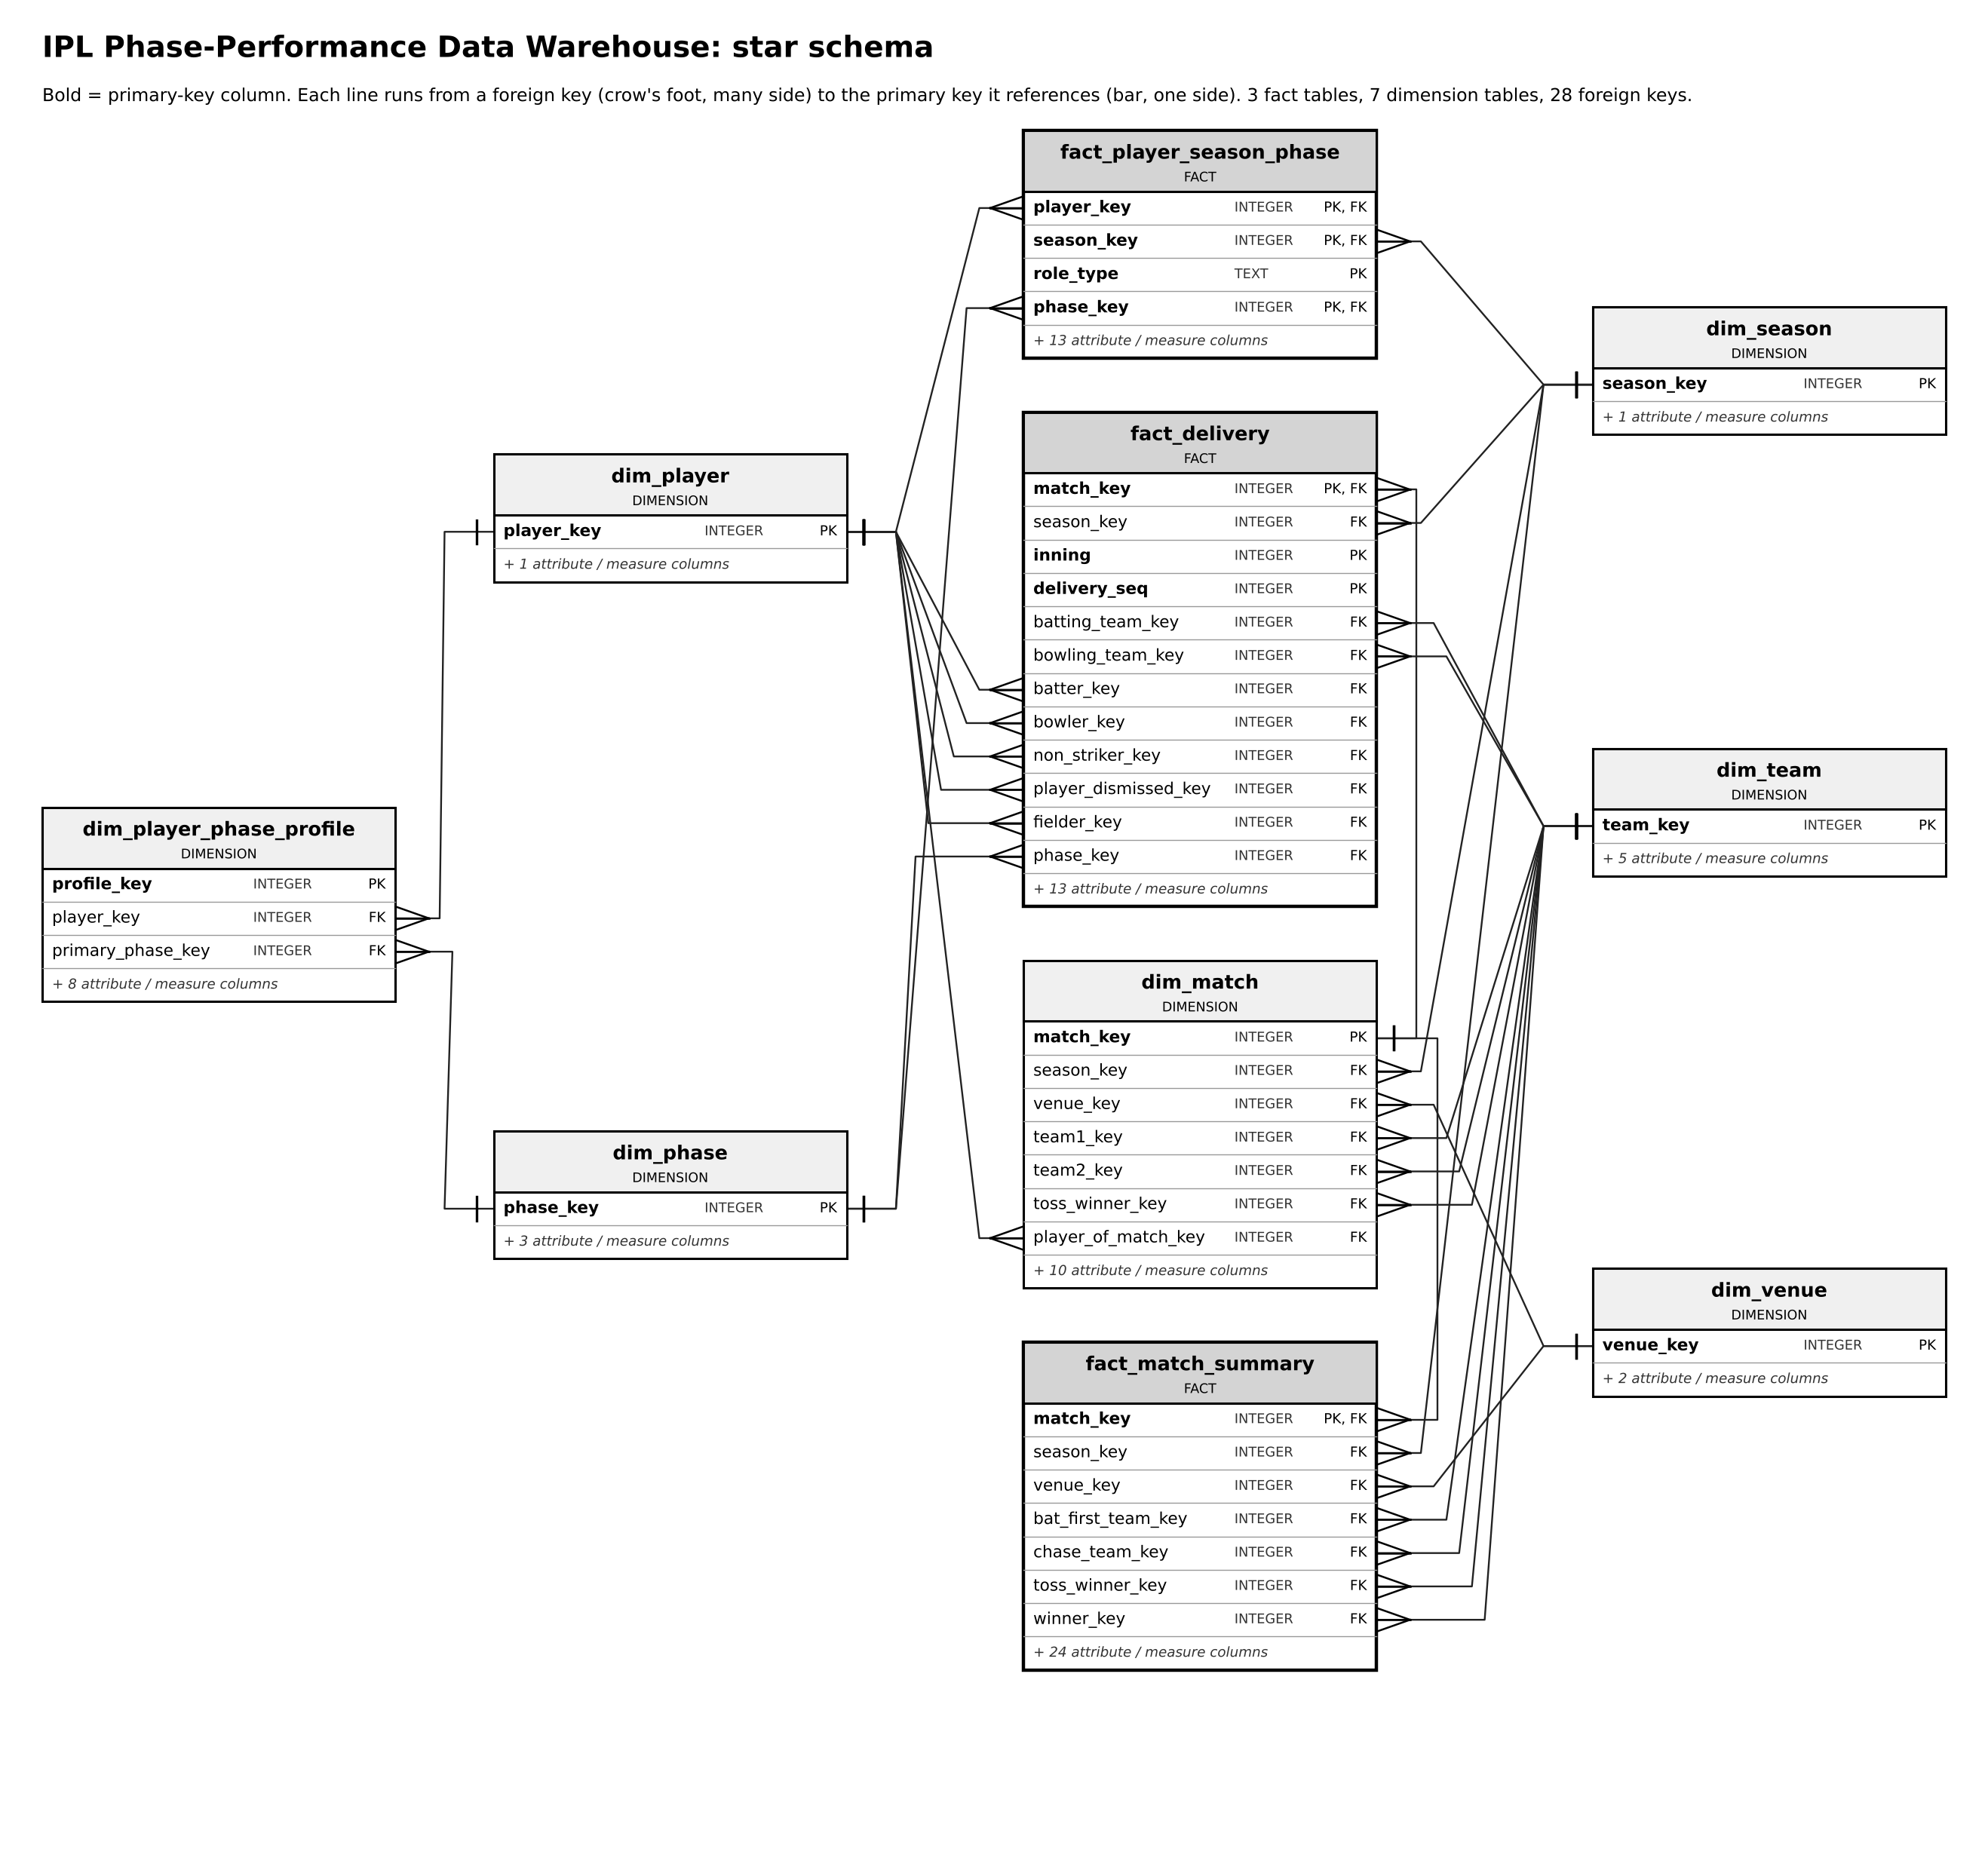

In [14]:
display(Image(REPO / "docs" / "er_diagram_keys.png", width=900))

In [15]:
tables = pd.read_sql("SELECT name, type FROM sqlite_master WHERE type IN ('table', 'view') "
                     "AND name NOT LIKE 'sqlite_%' ORDER BY type, name", con)
tables["rows"] = [con.execute(f'SELECT COUNT(*) FROM "{n}"').fetchone()[0] for n in tables.name]
tables[tables.name.str.match(r"(dim|fact|v)_")]

,name,type,rows
4,dim_match,table,1095
5,dim_phase,table,3
6,dim_player,table,741
7,dim_player_phase_profile,table,1187
8,dim_season,table,17
9,dim_team,table,18
10,dim_venue,table,36
11,fact_delivery,table,260920
12,fact_match_summary,table,1095
13,fact_player_season_phase,table,13695


A star-join query against the warehouse: 2024 Powerplay batting run rate by franchise.

In [16]:
pd.read_sql('''
    SELECT t.franchise_id, ROUND(SUM(f.total_runs) * 6.0 / SUM(f.is_legal_for_bowler), 2) AS pp_run_rate,
           SUM(f.is_wicket) AS wickets
    FROM fact_delivery f
    JOIN dim_team t   ON t.team_key = f.batting_team_key
    JOIN dim_phase p  ON p.phase_key = f.phase_key
    JOIN dim_season s ON s.season_key = f.season_key
    WHERE s.year = 2024 AND p.phase_name = 'Powerplay'
    GROUP BY t.franchise_id ORDER BY pp_run_rate DESC''', con)

,franchise_id,pp_run_rate,wickets
0,SRH,11.18,29
1,KKR,11.05,21
2,DEL,10.66,28
3,RCB,9.73,21
4,MI,9.37,25
5,PBKS,8.85,23
6,CSK,8.73,19
7,RR,8.59,19
8,LSG,8.27,26
9,GT,7.70,16


### 5.1 Validation gates
The pipeline refuses to export unless all nine gates pass. G4 and G5 list explained exceptions
(shortened matches; 7-ball overs) instead of hiding them.

In [17]:
pd.read_csv(LOGS / "validation_report.csv")[["gate", "description", "status", "failures", "detail"]]

,gate,description,status,failures,detail
0,G6,No raw team/venue/player string unmapped; distinct franchises = ex...,PASS,0,0 unmapped raw strings (0 rows); 15 franchises (expected 15)
1,G1,Referential integrity: every foreign key in every fact resolves to...,PASS,0,28 foreign keys checked
2,G2,"Grain: zero duplicates on (match, inning, delivery_seq)",PASS,0,0 duplicated grain keys
3,G3,total_runs = batsman_runs + extra_runs on every delivery,PASS,0,0 deliveries where total_runs != batsman_runs + extra_runs
4,G4,Completed regular matches: target_runs = first-innings total + 1 (...,PASS,0,1090 matches checked; 21 listed exceptions (shortened/D-L); 0 unex...
5,G5,Regular innings <= 120 legal balls; Super Over innings <= 6 (7-bal...,PASS,0,0 innings over the legal-ball limit unexplained; 29 seven-ball ove...
6,G7,"Winner is team1, team2 or an explicit non-result category",PASS,0,0 matches with an invalid winner
7,G8,SCD2 integrity: no overlapping spells; exactly one current row per...,PASS,0,0 overlapping spell pairs; 0 player-roles without exactly one curr...
8,G9,"Row-count reconciliation across raw, staging and warehouse",PASS,0,raw deliveries=260920; stg_deliveries=260920; clean_deliveries=260...


In [18]:
g5 = pd.read_csv(LOGS / "g5_exceptions.csv")
print(len(g5), "seven-ball overs (umpire miscounts), by season:", g5.merge(
    raw_m[["id", "date"]].astype({"id": int}), left_on="source_match_id", right_on="id").date.str[:4].value_counts().sort_index().to_dict())

29 seven-ball overs (umpire miscounts), by season: {'2008': 1, '2009': 1, '2010': 1, '2014': 1, '2018': 1, '2019': 1, '2020': 6, '2022': 3, '2023': 8, '2024': 6}


## 6. Insights

`analysis.run` answers six questions and saves every table and chart under
`data/export/analysis/`. The four headline insights follow, each backed by a chart or test.

In [19]:
res = analysis.run(P)
FIGS = EXPORT / "analysis" / "figures"
rates = res["q2_league_phase_rates"]

### Insight 1. The scoring boom is front-loaded: the Powerplay changed most

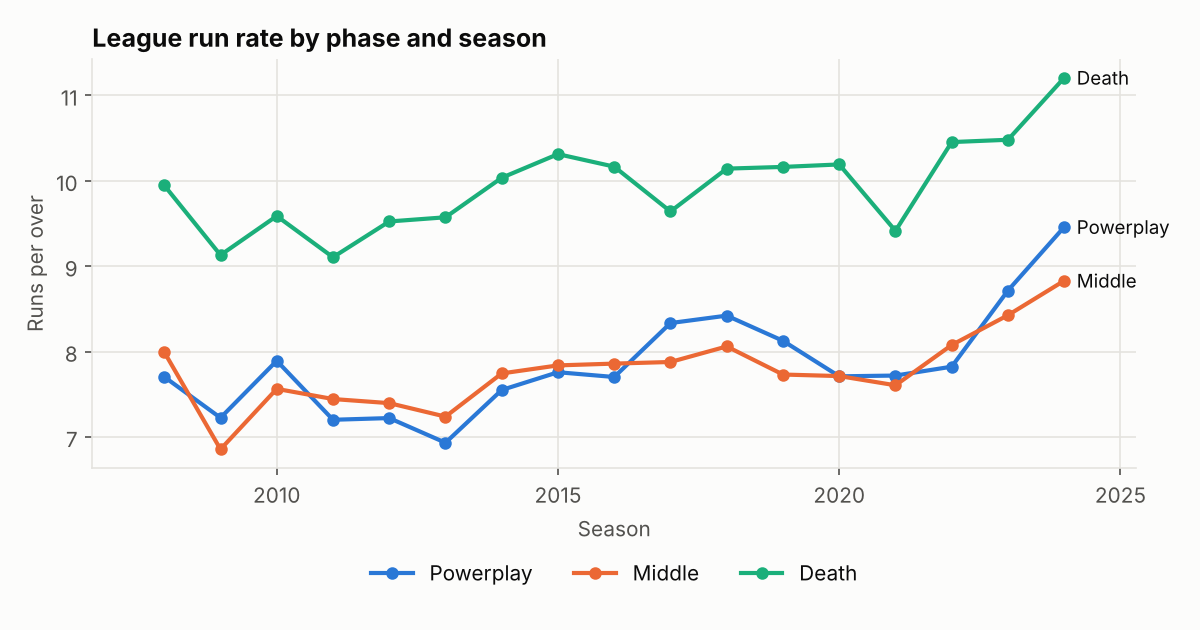

,2008,2022,2024,% change 2008-2024,% change 2022-2024
phase_name,,,,,
Powerplay,7.70,7.82,9.46,22.8,20.9
Middle,7.99,8.08,8.83,10.5,9.3
Death,9.95,10.45,11.21,12.7,7.2


Powerplay boundary % 2008 -> 2024: 19.69 -> 24.92 | dot-ball %: 49.68 -> 41.95
Average first-innings total: {2008: 161.0, 2022: 171.1, 2023: 183.5, 2024: 189.6}


In [20]:
display(Image(FIGS / "q2_league_phase_rates.png", width=760))
wide = rates.pivot(index="season", columns="phase_name", values="run_rate")[["Powerplay", "Middle", "Death"]]
change = pd.DataFrame({"2008": wide.loc[2008], "2022": wide.loc[2022], "2024": wide.loc[2024]})
change["% change 2008-2024"] = (100 * (change["2024"] / change["2008"] - 1)).round(1)
change["% change 2022-2024"] = (100 * (change["2024"] / change["2022"] - 1)).round(1)
display(change.round(2))
pp_rates = rates[rates.phase_name == "Powerplay"].set_index("season")
print("Powerplay boundary % 2008 -> 2024:", pp_rates.boundary_pct[2008], "->", pp_rates.boundary_pct[2024],
      "| dot-ball %:", pp_rates.dot_pct[2008], "->", pp_rates.dot_pct[2024])
fms_all = pd.read_sql("SELECT s.year, AVG(inn1_total_runs) AS avg_first_innings FROM fact_match_summary f "
                      "JOIN dim_season s USING (season_key) WHERE match_status = 'completed' GROUP BY 1", con)
print("Average first-innings total:", fms_all.set_index("year").avg_first_innings.round(1).loc[[2008, 2022, 2023, 2024]].to_dict())

**Finding.** The Powerplay run rate rose from 7.70 to 9.46 runs per over between 2008 and 2024
(+23%), against +10.5% for the Middle overs and +12.7% for the Death overs. Most of that jump is
recent: +21% between 2022 and 2024 alone, the first two seasons of the Impact Player rule. Batters
now hit a boundary off 24.9% of balls faced in the Powerplay (19.7% in 2008) and the dot-ball
share has fallen from 49.7% to 42.0%. Average first-innings totals went from 171 in 2022 to 190
in 2024. The common belief is that T20 scoring grew through Death-overs hitting; the data says the
biggest change since 2022 is at the start of the innings. (Association only: the rule change is a
plausible cause, not a proven one.)

### Insight 2. Winning the Powerplay is a strong but not decisive signal

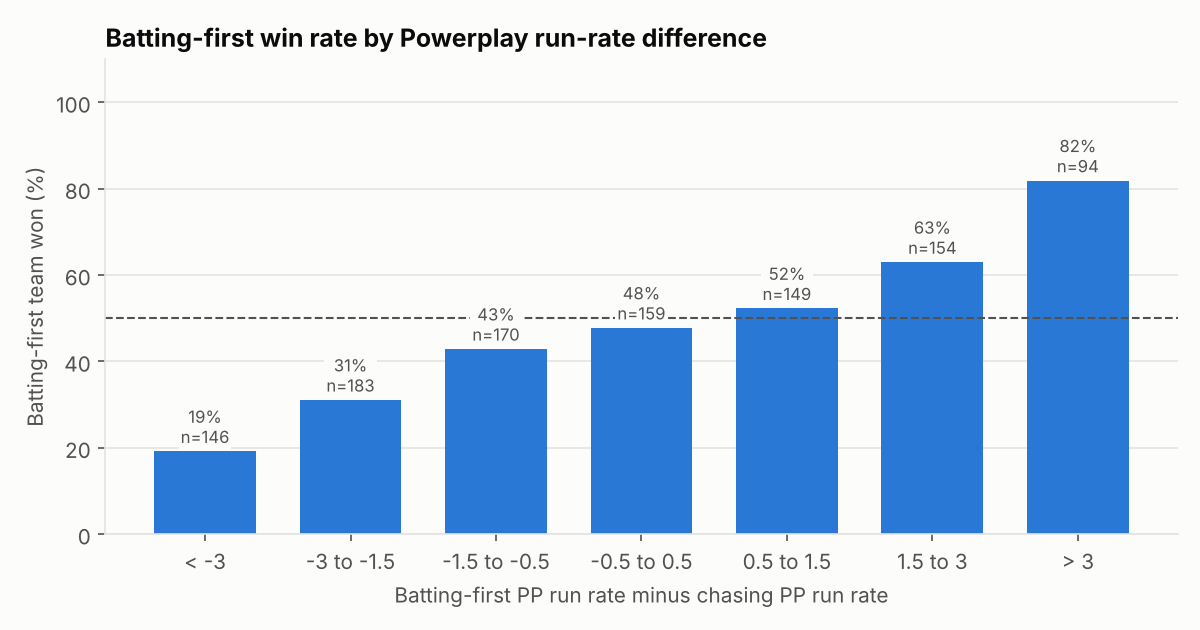

,measure,matches,point_biserial_r,p_value,higher_pp_rate_wins_pct
0,inn1_pp_run_rate,1055,0.240,0.0,65.5
1,inn1_pp_wickets,1055,-0.222,0.0,65.5
2,pp_rr_diff,1055,0.355,0.0,65.5


,pp_rr_diff_band,matches,wins,bat_first_win_pct
0,< -3,146,28,19.2
1,-3 to -1.5,183,57,31.1
2,-1.5 to -0.5,170,73,42.9
3,-0.5 to 0.5,159,76,47.8
4,0.5 to 1.5,149,78,52.3
5,1.5 to 3,154,97,63.0
6,> 3,94,77,81.9


In [21]:
display(Image(FIGS / "q6_powerplay_win_rate.png", width=760))
display(res["q6_powerplay_correlation"])
res["q6_powerplay_win_rate"]

**Finding.** Across 1,055 completed, full-length matches, the side with the higher Powerplay run
rate won 65.5% of the time. The effect is graded: when the team batting first out-scores the
chasers' Powerplay by more than 3 runs an over it wins 82% of matches; when it is out-scored by
more than 3 an over it wins only 19%. The point-biserial correlation between the Powerplay
run-rate difference and the result is 0.36, so the first six overs carry real information, but a
third of matches are still won by the side that lost the Powerplay.

### Insight 3. The toss itself is a coin flip; the decision after it is not

In [22]:
display(res["q5_toss_overall"])
field_share = pd.read_sql("SELECT s.year, ROUND(100.0 * AVG(toss_decision = 'field'), 1) AS pct_chose_field "
                          "FROM fact_match_summary f JOIN dim_season s USING (season_key) GROUP BY 1", con)
print(field_share.set_index("year").pct_chose_field.loc[[2008, 2012, 2016, 2019, 2022, 2024]].to_dict())
res["q5_toss_by_venue"].head(8)

,toss_decision,matches,toss_winner_won,win_pct,chi2,p_value,dof,total_matches,overall_toss_winner_win_pct
0,bat,390,177,45.4,6.859,0.0088,1,1090,50.8
1,field,700,377,53.9,6.859,0.0088,1,1090,50.8


{2008: 55.2, 2012: 50.0, 2016: 81.7, 2019: 83.3, 2022: 79.7, 2024: 73.2}


,venue,matches,pct_chose_field,toss_winner_win_pct,chi2,p_value
0,Wankhede Stadium,118,74.6,52.5,0.286,0.5929
1,Eden Gardens,93,67.7,52.7,2.158,0.1418
2,M Chinnaswamy Stadium,91,90.1,53.8,0.059,0.8074
3,Arun Jaitley Stadium,89,60.7,50.6,0.007,0.9320
4,MA Chidambaram Stadium,85,43.5,49.4,1.482,0.2234
5,Rajiv Gandhi International Stadium,77,54.5,36.4,1.123,0.2893
6,Punjab Cricket Association IS Bindra Stadium,61,72.1,47.5,0.818,0.3657
7,Sawai Mansingh Stadium,57,56.1,52.6,3.824,0.0505


**Finding.** Toss winners won 50.8% of decided matches, which is no better than chance. But toss
winners who chose to **field** won 53.9% (377 of 700) against 45.4% (177 of 390) for those who
chose to bat; a chi-square test of independence gives χ² = 6.86, p = 0.009. Captains have learned
this: the share choosing to field moved between 35% and 66% a season before 2014, then stayed above
80% every season from 2016 to 2019. No
single venue shows a significant toss effect on its own (all p > 0.05 with 27–118 matches each), so
the overall effect is small and should not be over-read at ground level.

### Insight 4. A player's "phase" is not a fixed trait

In [23]:
display(res["q1_drift_summary"])
moves = res["q1_drift_moves"]
display(moves.pivot_table(index=["role_type", "from_phase"], columns="to_phase", values="n", fill_value=0))
res["q1_worked_examples"]

,threshold_balls,role_type,qualifying_player_seasons,players_with_2plus_qualifying_seasons,phase_changes,players_who_changed
0,60,batting,1159,188,269,115
1,60,bowling,1250,241,271,134
2,120,batting,812,132,175,83
3,120,bowling,843,150,166,81


to_phase              Death  Middle  Powerplay
role_type from_phase                          
batting   Death         0.0    64.0       16.0
          Middle       62.0     0.0       59.0
          Powerplay    12.0    56.0        0.0
bowling   Death         0.0    40.0       64.0
          Middle       37.0     0.0       31.0
          Powerplay    63.0    36.0        0.0

,player,player_key,role_type,from_phase,to_phase,from_season,to_season,seasons_between,from_phase_index_before,to_phase_index_before,from_phase_index_after,to_phase_index_after,index_shift
0,Anuj Rawat,86,batting,Powerplay,Death,2022,2023,1,2.264,0.260,0.183,2.676,2.416
1,SS Tiwary,628,batting,Middle,Death,2013,2015,2,1.294,1.024,0.506,3.403,2.379
2,M Shahrukh Khan,367,batting,Middle,Death,2022,2023,1,1.365,1.340,0.324,3.675,2.335


**Finding.** Among players with at least two qualifying seasons (60+ balls), 115 of 188 batters
(61%) and 134 of 241 bowlers (56%) changed their primary phase at least once. The result holds at
a stricter 120-ball threshold (63% of batters, 54% of bowlers), so it is not small-sample noise.
The *type* of move differs by role: 90% of batters' moves (241 of 269) involve the Middle overs,
which is a batter moving one slot up or down the order, while 47% of bowlers' moves (127 of 271)
are straight swaps between the Powerplay and the Death, the two specialist new-ball and
end-of-innings roles. Scouting a player by "he is a Death bowler" is therefore a statement about
one season, not about the player.

### Supporting views: venues and teams

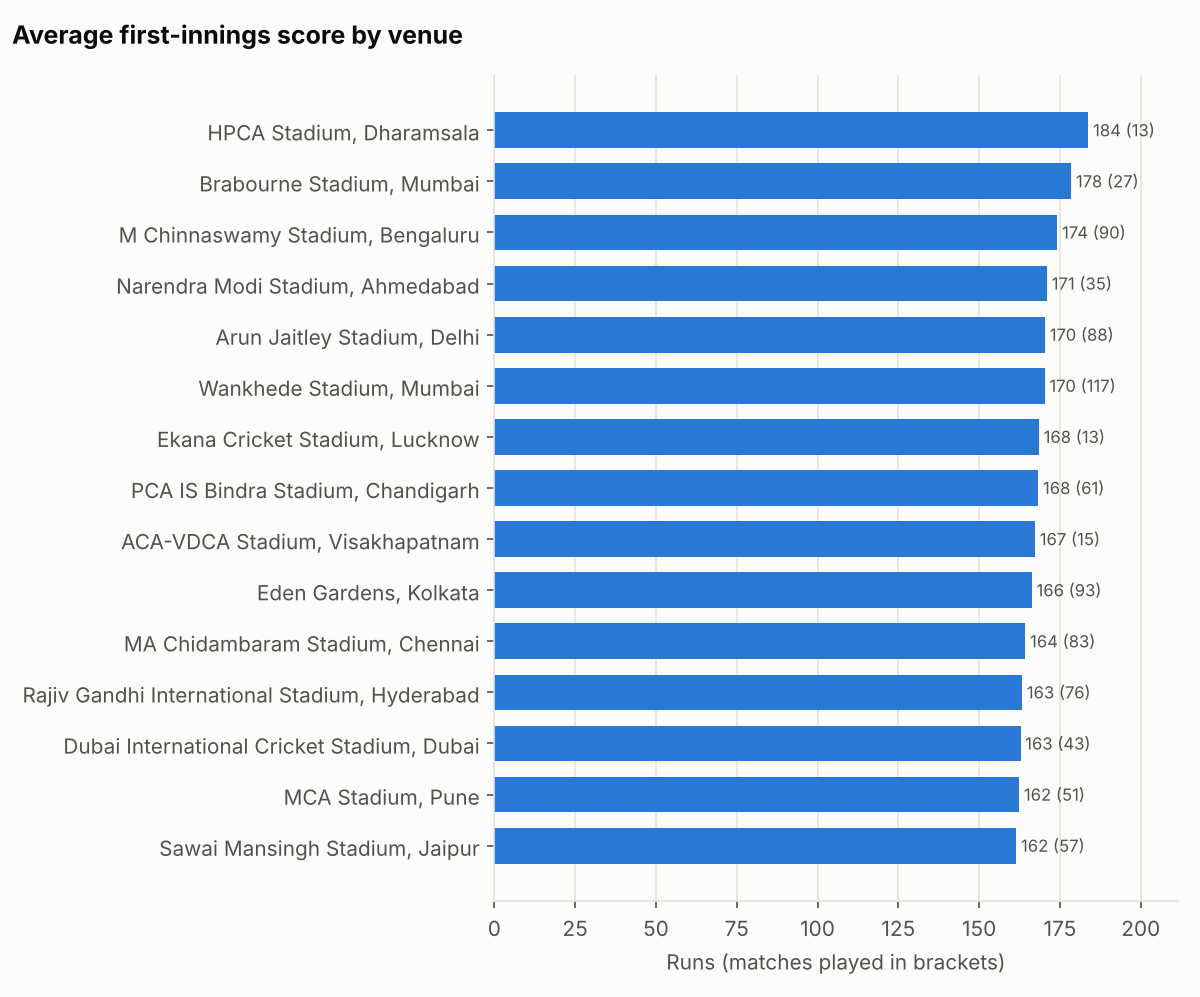

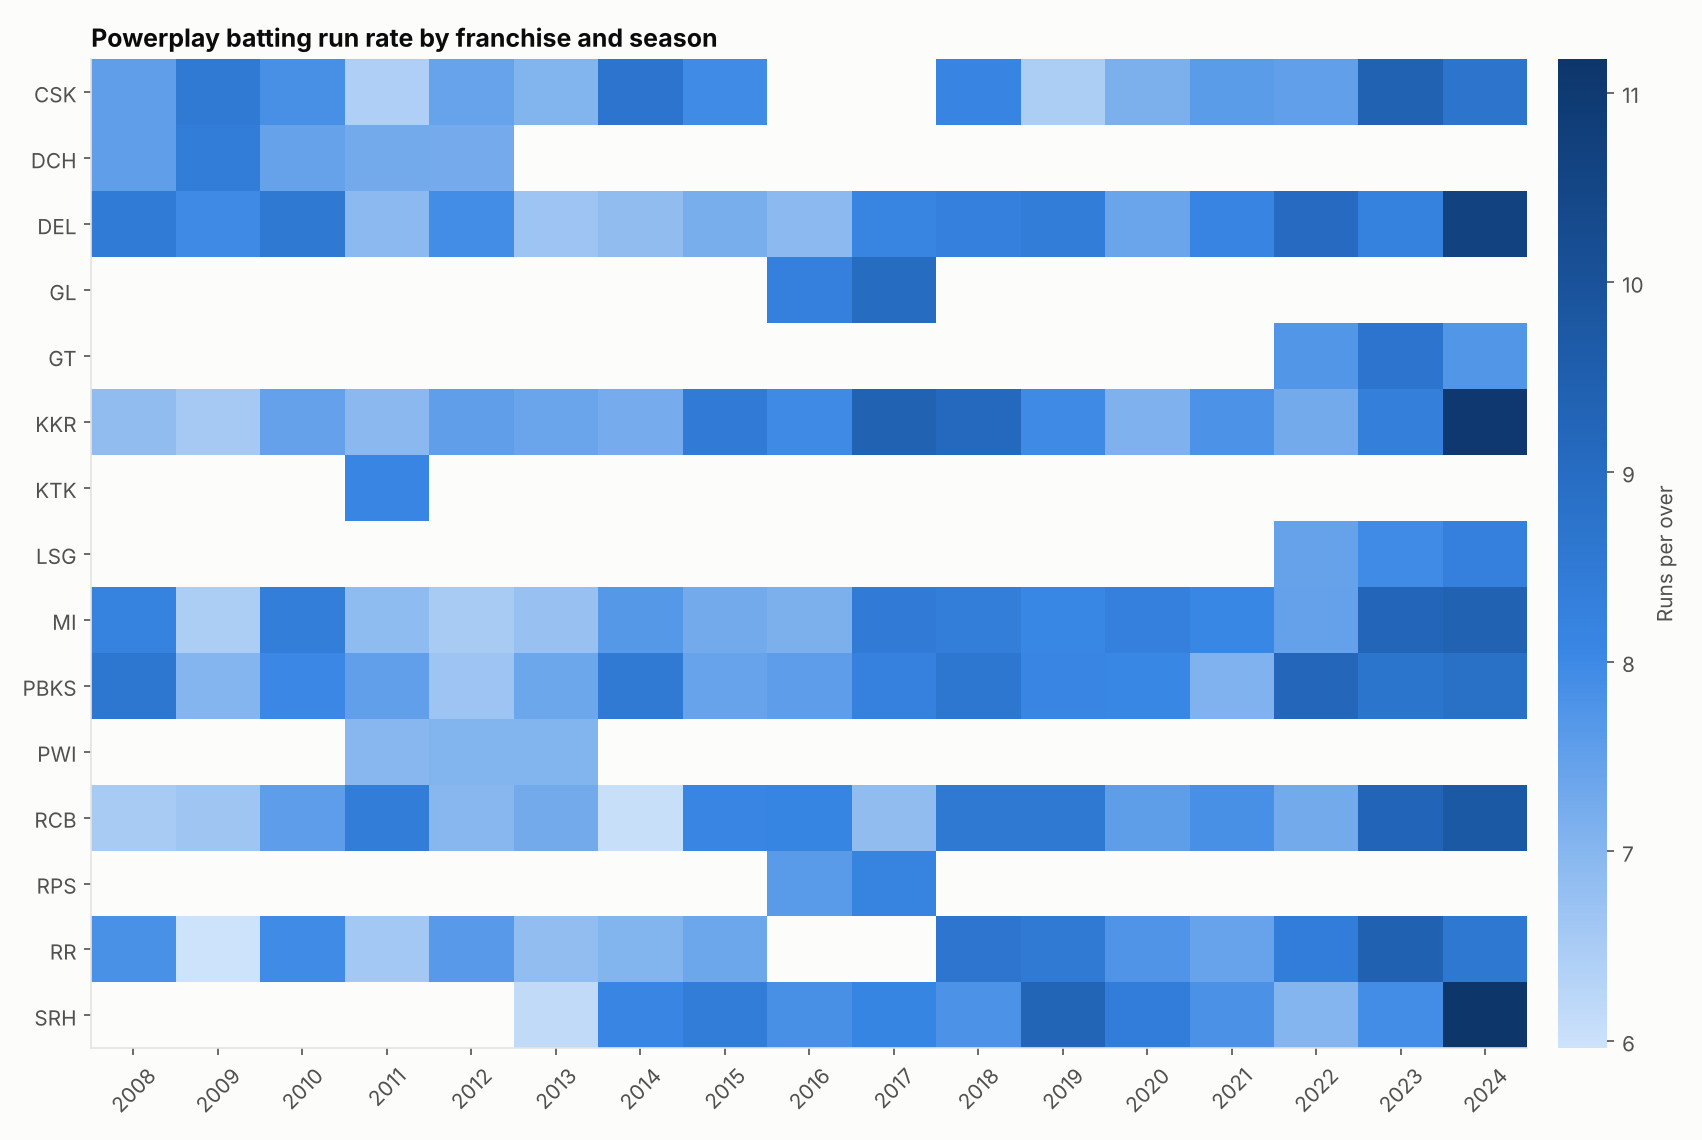

In [24]:
display(Image(FIGS / "q4_venues.png", width=640))
display(Image(FIGS / "q3_team_powerplay_heatmap.png", width=760))

Dharamsala (184) and the Brabourne (178) have the highest average first-innings totals but few
matches; among grounds with many matches, Bengaluru's Chinnaswamy (174 over 90 matches) is the
high-scoring outlier. At Jaipur's Sawai Mansingh the side batting first won only 35% of 57
matches. The franchise heatmap shows the league-wide jump in 2023–24, with SRH and KKR posting the
highest Powerplay run rates of any team-season in 2024.

## 7. Machine learning: does the Powerplay predict the winner?

**Task.** Binary classification. Target `bat_first_won` = 1 if the team batting first won.
Only completed, full-length matches without a Super Over or D-L are used (1,055 matches).

**Two prediction points**, so the model never sees information from after the moment it predicts:

* **Model A**: after the first-innings Powerplay (that Powerplay, toss, venue history, both teams'
  previous-season win %).
* **Model B**: after both Powerplays (adds the chasing side's Powerplay).

**Algorithms.** Logistic regression (interpretable, linear), a decision tree (readable rules) and
a random forest (non-linear, lower variance), each compared with two baselines: always predicting
the training majority class, and a cricket rule of thumb ("higher Powerplay run rate wins").

**Methodology.**
* Chronological split by season: train 2008–2021, validation 2022, test 2023–2024. A random split
  would let the model learn from future seasons.
* Preprocessing (median imputation, scaling) sits inside a scikit-learn `Pipeline`, so it is fitted
  on training folds only.
* Hyper-parameters are chosen by **forward-chaining cross-validation**: each fold trains on all
  earlier seasons and validates on the next one (14 folds), scored by ROC-AUC.
* The final models are refitted on train + validation and score the test seasons **once**.

In [25]:
mres = ml.run(P)
MLF = EXPORT / "ml" / "figures"
display(mres["split"])
cv = mres["cv_results"]
cv.loc[cv.groupby(["feature_set", "model"]).cv_roc_auc.idxmax(),
       ["feature_set", "model", "C", "max_depth", "min_samples_leaf", "folds", "cv_roc_auc"]]

,part,seasons,matches
0,train,2008 2009 2010 2011 2012 2013 2014 2015 2016 2017 2018 2019 2020 2021,839
1,val,2022,74
2,test,2023 2024,142


,feature_set,model,C,max_depth,min_samples_leaf,folds,cv_roc_auc
11,A,decision_tree,NaN,5,20,14,0.599510
1,A,logistic_regression,0.1,NaN,NaN,14,0.640035
12,A,random_forest,NaN,3,5,14,0.643342
25,B,decision_tree,NaN,3,20,14,0.685124
19,B,logistic_regression,0.1,NaN,NaN,14,0.750725
32,B,random_forest,NaN,5,5,14,0.729573


,feature_set,model,params,accuracy,precision,recall,f1,roc_auc
0,A,baseline_majority,,0.479,0.000,0.000,0.000,0.500
1,A,baseline_pp_rate_above_train_median,,0.592,0.575,0.824,0.678,0.666
3,A,logistic_regression,{'C': 0.1},0.606,0.622,0.622,0.622,0.663
5,A,decision_tree,"{'max_depth': 5, 'min_samples_leaf': 20}",0.563,0.611,0.446,0.516,0.585
7,A,random_forest,"{'max_depth': 3, 'min_samples_leaf': 5}",0.592,0.618,0.568,0.592,0.656
8,B,baseline_majority,,0.479,0.000,0.000,0.000,0.500
9,B,baseline_higher_pp_rate_wins,,0.669,0.701,0.635,0.667,0.729
11,B,logistic_regression,{'C': 0.1},0.683,0.723,0.635,0.676,0.732
13,B,decision_tree,"{'max_depth': 3, 'min_samples_leaf': 20}",0.655,0.705,0.581,0.637,0.685
15,B,random_forest,"{'max_depth': 5, 'min_samples_leaf': 5}",0.662,0.710,0.595,0.647,0.751


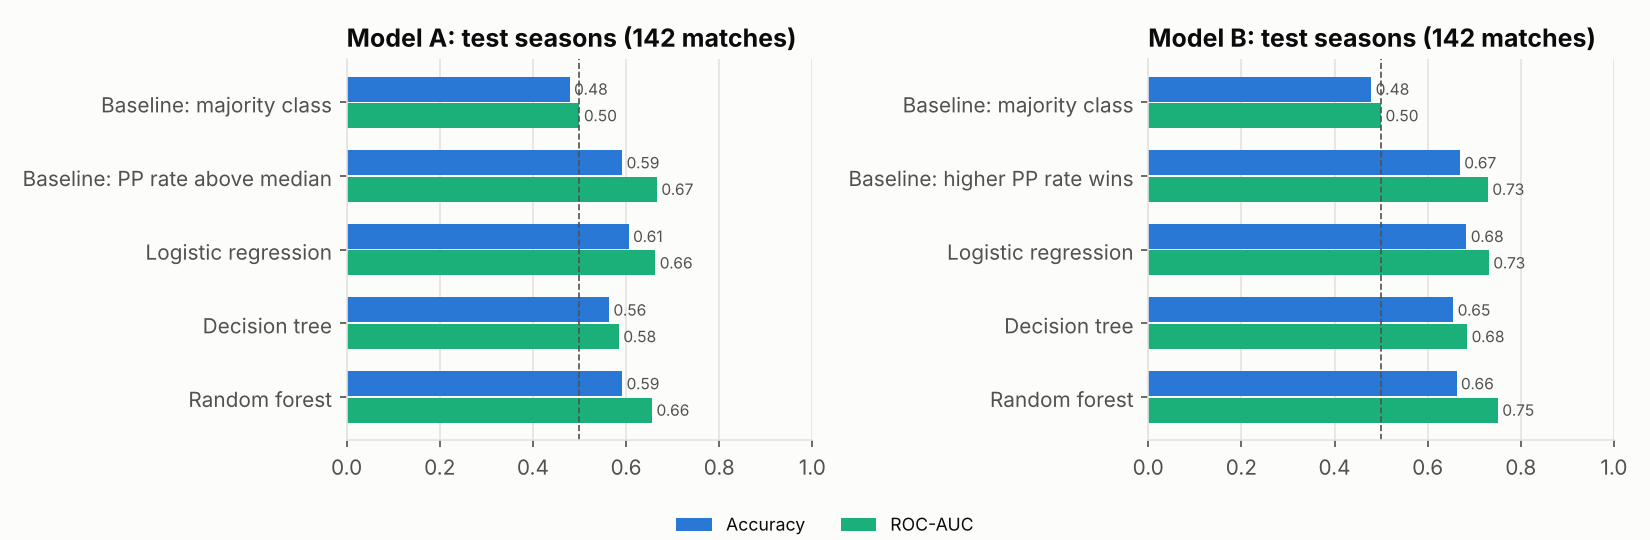

In [26]:
m = mres["metrics"]
test = m[m.split == "test"][["feature_set", "model", "params", "accuracy", "precision", "recall", "f1", "roc_auc"]]
display(test.round(3))
display(Image(MLF / "model_comparison.png", width=820))

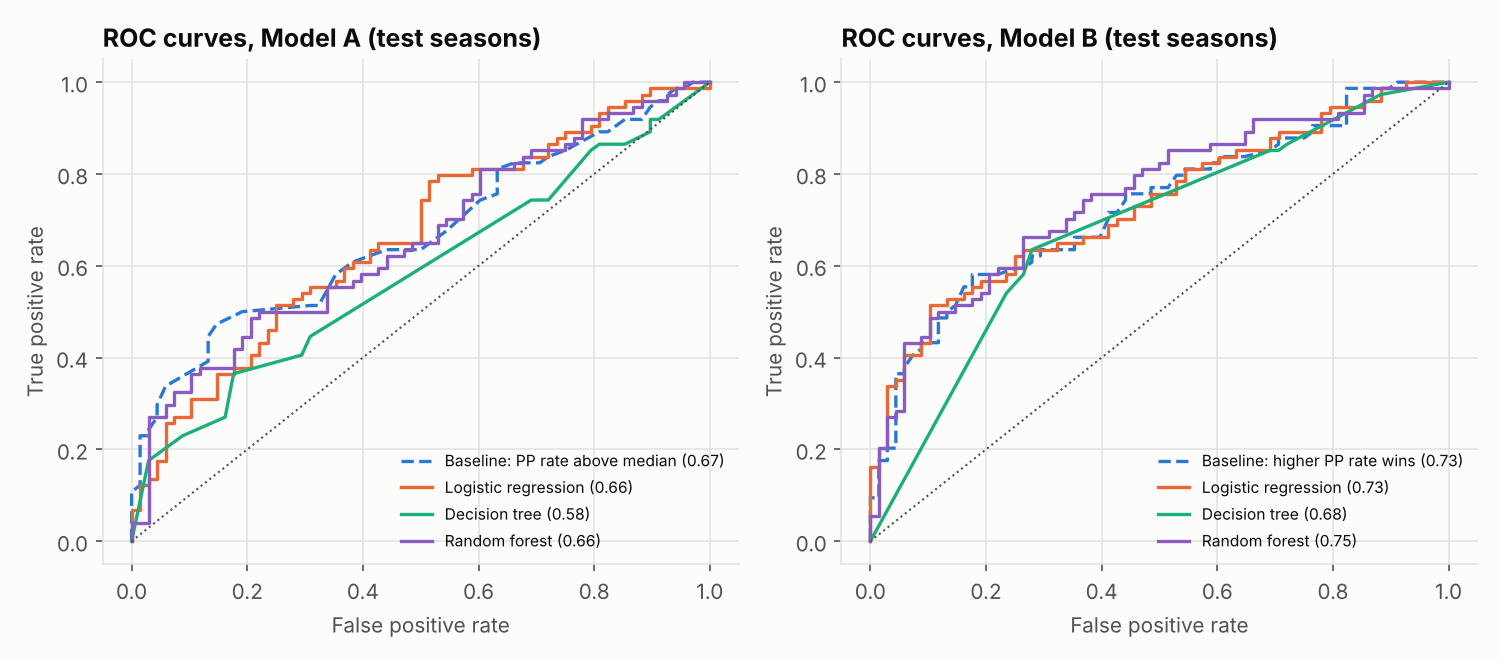

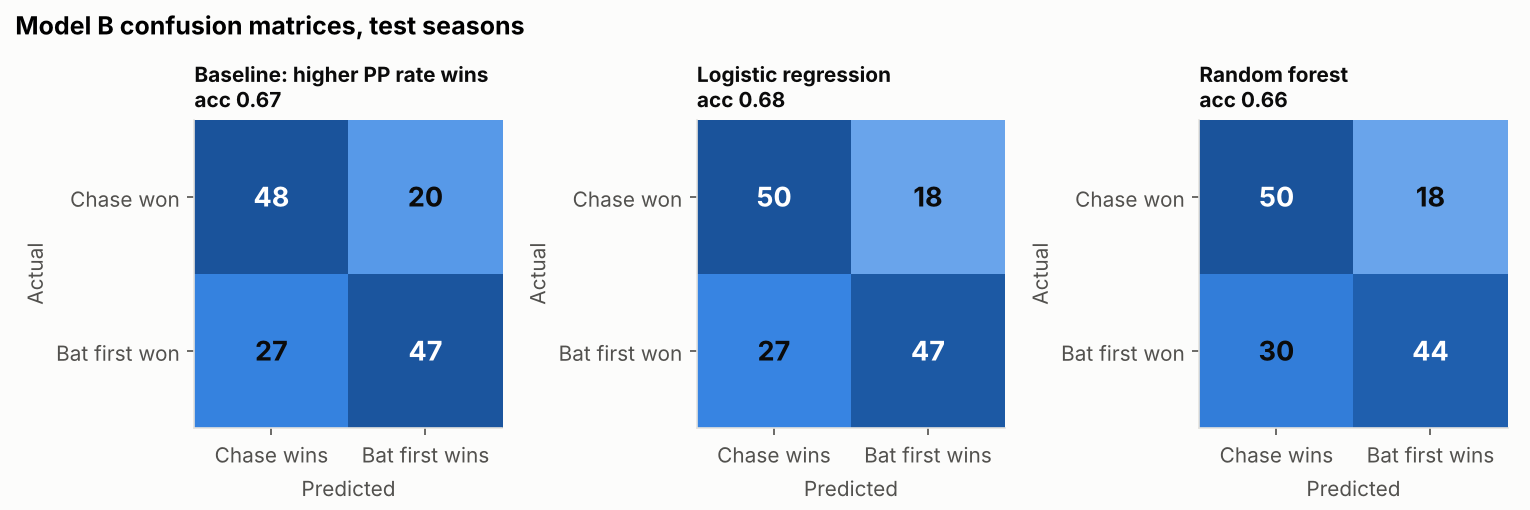

In [27]:
display(Image(MLF / "roc_test.png", width=820))
display(Image(MLF / "confusion_matrices.png", width=820))

model,decision_tree,logistic_regression,random_forest
feature,,,
inn2_pp_wickets,0.671,0.703,0.233
inn1_pp_runs,0.076,0.157,0.096
inn2_pp_runs,0.000,-0.127,0.084
inn1_pp_run_rate,0.000,0.160,0.081
inn2_pp_run_rate,0.000,-0.132,0.079
inn1_pp_wickets,0.128,-0.346,0.078
inn1_pp_dot_pct,0.075,-0.074,0.074
inn2_pp_boundaries,0.050,-0.258,0.070
inn1_pp_boundaries,0.000,0.026,0.047


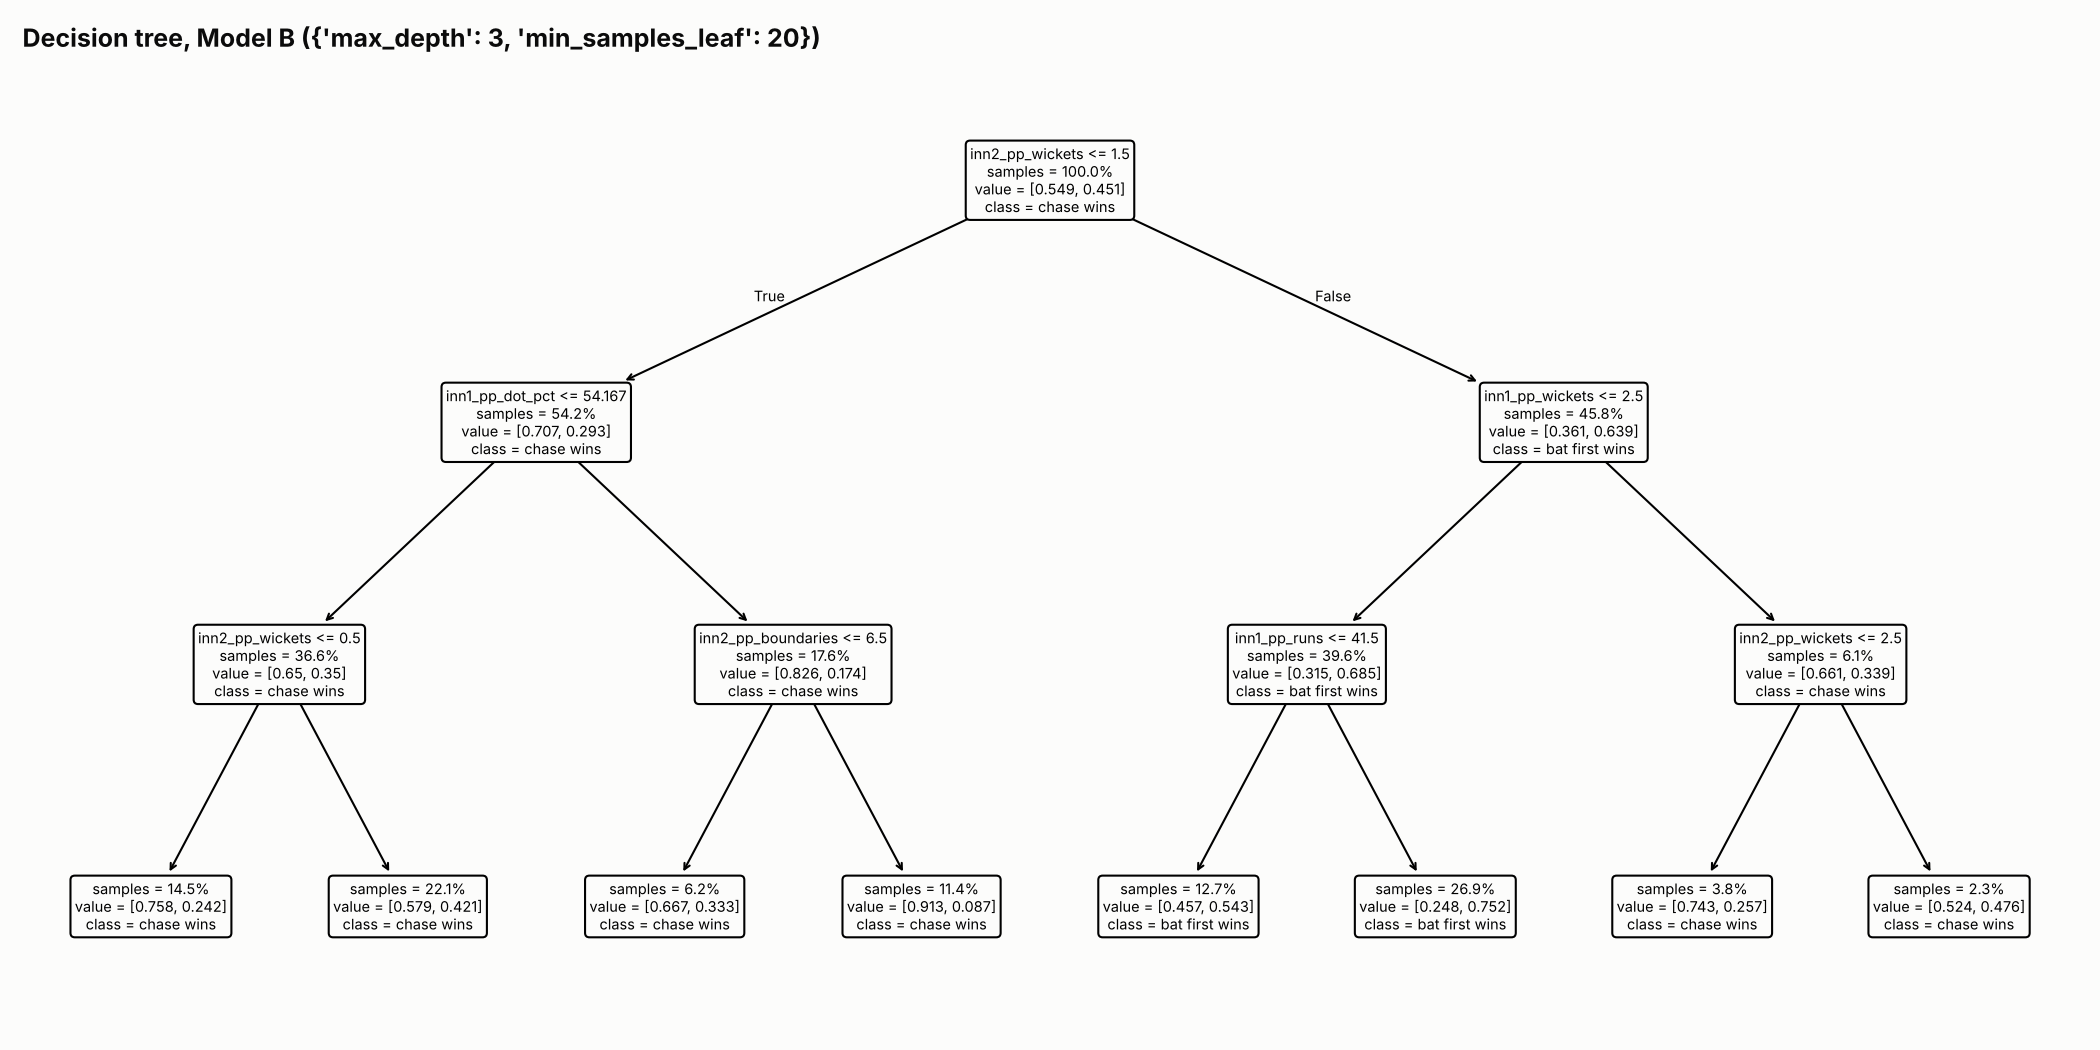

In [28]:
imp = mres["feature_importance"]
display(imp[imp.feature_set == "B"].pivot_table(index="feature", columns="model", values="value")
        .sort_values("random_forest", ascending=False).round(3))
display(Image(MLF / "decision_tree_model_B.png", width=900))

In [29]:
preds = mres["test_predictions"]
lr_b = preds[(preds.feature_set == "B") & (preds.model == "logistic_regression")]
print("Model B logistic regression accuracy by test season:", lr_b.groupby("season").correct.mean().round(3).to_dict())
feats = pd.read_csv(EXPORT / "ml_features.csv")
print("Batting-first win rate, training seasons vs test seasons:",
      round(feats[feats.season <= 2021].bat_first_won.mean(), 3), "vs",
      round(feats[feats.season >= 2023].bat_first_won.mean(), 3))
ups = mres["upsets"]
print("Confident (>= 70%) wrong predictions on the test seasons:")
ups.groupby(["feature_set", "model"]).size()

Model B logistic regression accuracy by test season: {2023: 0.662, 2024: 0.704}
Batting-first win rate, training seasons vs test seasons: 0.447 vs 0.521
Confident (>= 70%) wrong predictions on the test seasons:


feature_set  model              
A            decision_tree          21
             logistic_regression     7
             random_forest           5
B            decision_tree          27
             logistic_regression    18
             random_forest          10
dtype: int64

**Results and interpretation.**

* **Model A (first-innings Powerplay only)** is weak. The best model, logistic regression, reaches
  60.6% accuracy and ROC-AUC 0.66 on 2023–24, no better than the one-line rule "batting first
  wins if its Powerplay run rate is above the training median" (59.2%, AUC 0.67). Six overs of one
  innings say little about a 40-over match.
* **Model B (both Powerplays)** is clearly better: logistic regression 68.3% accuracy, precision
  0.72, recall 0.64, F1 0.68, ROC-AUC 0.73; the random forest has the best AUC (0.75) but lower
  accuracy (66.2%). Both beat the majority baseline (47.9%) by a wide margin, **but only just beat
  the rule "higher Powerplay run rate wins" (66.9%, AUC 0.73)**. The honest conclusion is that most
  of the signal is captured by one subtraction; the models add one or two percentage points.
* **What drives it.** The strongest single feature in every Model B is the *chasing side's
  Powerplay wickets*, not a run rate: it is the root split of the decision tree, the largest
  logistic-regression coefficient and a quarter of the forest's importance. In the seasons the
  final models were fitted on (2008–2022), chasers who lost at most one Powerplay wicket won 71%
  of the time; those who lost two or
  more won 36%. Team form from the previous season and venue history add almost nothing.
* **Where it underperforms.** Recall for batting-first wins is only 0.64 (27 of 74 missed), and
  2023 was harder than 2024 (66% vs 70% accuracy). The base rate also shifted: batting first won
  45% of training matches but 52% of test matches, which is why the majority baseline falls below
  50%. The Impact Player rule from 2023 changed the game the model was trained on; a 2025 model
  should weight recent seasons more. With 142 test matches, one match is 0.7 percentage points of
  accuracy, so differences of 1–2 points between models are within noise.

## 8. Export for the Power BI dashboard
The dashboard reads one workbook, `data/export/powerbi/IPL_PowerBI_Data.xlsx` (one Excel table per
sheet, also written as CSVs), containing the star-schema tables with names denormalised for easy
slicing, plus the model outputs (test predictions vs actual, metrics and feature importance). The
build steps, relationships and DAX measures are in `docs/PowerBI_Build_Guide.docx`.

In [30]:
pbi = powerbi.run(P)
pd.DataFrame([(k, len(v), len(v.columns)) for k, v in pbi.items()], columns=["table", "rows", "columns"])

,table,rows,columns
0,Season,17,3
1,Phase,3,5
2,Venue,36,5
3,Franchise,15,3
4,Team,18,6
5,Player,741,2
6,Role,2,1
7,Matches,1095,38
8,TeamMatches,2190,9
9,InningsPhase,6443,13


## 9. Limitations

* **What the data cannot tell us.** There is no ball-tracking, field-placement, pitch or weather
  data, no batting order and no information on the Impact Player substitutions themselves, so we
  can describe *when* players bat or bowl but not *why* their role changed, and we cannot separate
  the Impact Player rule from other changes in 2023–24 (new venues, new franchises, player
  turnover).
* **Phase is a proxy for role.** A batter's phase share depends on how long the batters above him
  last. A top-order batter on a strong side can look like a Death batter in a season when the
  openers kept going. The phase index removes the league-wide effect, not the team effect.
* **Thresholds are choices.** Who counts as having "changed phase" depends on the 60-ball
  qualification threshold; we report 120 balls as well, and the headline percentages move by only
  2–3 points, but individual players can flip.
* **Wrangling decisions that could bias results.** Renamed grounds are merged (Feroz Shah Kotla
  and Arun Jaitley Stadium are one venue), which assumes the pitch did not change with the name;
  franchises keep their history across renames (Delhi Daredevils → Delhi Capitals), which assumes
  continuity; 7-ball overs are kept as bowled; shortened, D-L and Super Over matches are left out
  of the ML set (40 matches), which slightly favours "normal" games.
* **Small test set and a moving target.** 142 test matches give wide confidence intervals, and the
  game itself changed between training and test seasons.
* **Correlation, not causation.** The toss and Powerplay findings are associations in
  observational data.

## 10. Conclusion
The wrangling work (entity resolution of 19 team strings and 58 venue strings, the legal-ball and
phase logic, a delivery-grain star schema with SCD Type 2 history and nine validation gates) is
what makes the questions answerable at all. The answers: most players' primary phase is not
stable from season to season; the Powerplay has changed more than any other phase since the Impact
Player rule; and while the two Powerplays predict the winner about two-thirds of the time, most of
that signal is captured by a one-line rule, with Powerplay wickets in the chase mattering more
than Powerplay runs.

In [31]:
con.close()
print("Notebook finished without errors.")

Notebook finished without errors.
